  t=0: min p = 0.2500 (GEM lobes: 0.1), min rho = 0.5000 (GEM: 0.2)
/Users/evandaniels/Research/runs/gem/di_0_res1: 81 outputs, E_tot(0) = 293.670228, E_mag(0) = 151.590228
  t=0: min p = 0.1000 (GEM lobes: 0.1), min rho = 0.2000 (GEM: 0.2)
/Users/evandaniels/Research/runs/gem/di_0.0_rk3_poynting: 81 outputs, E_tot(0) = 219.429698, E_mag(0) = 151.077698
  t=0: min p = 0.1000 (GEM lobes: 0.1), min rho = 0.2000 (GEM: 0.2)
/Users/evandaniels/Research/runs/gem/di_0.0_rk3_nopoynting: 81 outputs, E_tot(0) = 219.429698, E_mag(0) = 151.077698

run                   dE_tot/E_tot0     dE_mag   dE_other  (at t_final)
di = 0 (old)              2.398e-11   -14.3588    14.3588
di = 0 (poynting)         2.646e-11   -11.6502    11.6502
di = 0 (no poynting)      3.074e-11   -13.5403    13.5403


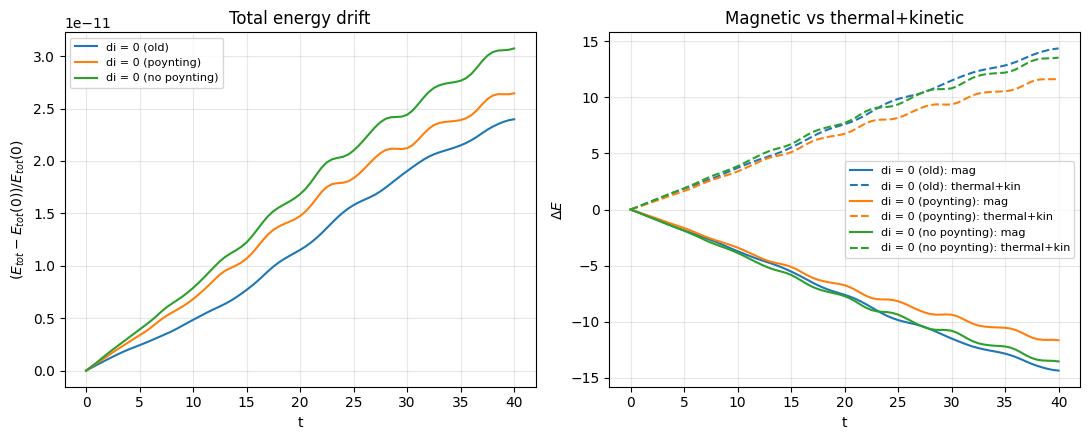

In [5]:
"""
energy_check.py -- total-energy conservation for GEM d_i=0 runs

E_tot(t) = integral of U dx dy   (U = p/(g-1) + rho v^2/2 + B^2/2)
E_mag(t) = integral of (Bx^2+By^2+Bz^2)/2
E_oth    = E_tot - E_mag         (thermal + kinetic)

With conducting y-walls and periodic x, E_tot should be flat apart from a small
wall flux. Joule heating should show up as E_mag falling and E_oth rising by the
same amount, so Delta E_tot stays ~0.
"""
import os, glob
import numpy as np
import matplotlib.pyplot as plt

BASE = os.path.expanduser('~/Research/runs')
RUNS = {
    'di = 0 (old)':      'gem/di_0_res1',
    'di = 0 (poynting)': 'gem/di_0.0_rk3_poynting',
    'di = 0 (no poynting)': 'gem/di_0.0_rk3_nopoynting'
}
P, DT_OUT, T_FINAL = 10, 0.5, 40.0

def load(run_dir, name, n):
    return np.vstack([np.loadtxt(f'{run_dir}/{name}_files/{name}_p{p:03d}_{n:03d}')
                      for p in range(P)])

GAMMA = 5.0/3.0
VEL_IS_MOMENTUM = False   # set True if u1,u2,u3 turn out to be rho*v rather than v

def analyze(run_dir):
    y = np.loadtxt(f'{run_dir}/mesh_files/y')
    x = np.concatenate([np.loadtxt(f'{run_dir}/mesh_files/x_p{p:03d}') for p in range(P)])
    dA = np.gradient(x).mean() * np.gradient(y).mean()
    N = len(glob.glob(f'{run_dir}/b2_files/b2_p000_*'))

    t, Et, Em, Ek, Eth = [], [], [], [], []
    for n in range(N):
        tn = n * DT_OUT
        if tn > T_FINAL + 1e-9:
            break
        rho = load(run_dir, 'rho', n)
        p   = load(run_dir, 'p', n)
        u2  = sum(load(run_dir, u, n)**2 for u in ('u1', 'u2', 'u3'))
        B2  = sum(load(run_dir, b, n)**2 for b in ('b1', 'b2', 'b3'))
        ek  = 0.5*u2/rho if VEL_IS_MOMENTUM else 0.5*rho*u2
        if n == 0:
            print(f'  t=0: min p = {p.min():.4f} (GEM lobes: 0.1), '
                  f'min rho = {rho.min():.4f} (GEM: 0.2)')
        t.append(tn)
        Eth.append((p/(GAMMA-1)).sum()*dA)
        Ek.append(ek.sum()*dA)
        Em.append(0.5*B2.sum()*dA)
    t, Eth, Ek, Em = map(np.array, (t, Eth, Ek, Em))
    Et = Eth + Ek + Em
    print(f'{run_dir}: {len(t)} outputs, E_tot(0) = {Et[0]:.6f}, E_mag(0) = {Em[0]:.6f}')
    return t, Et, Em


res = {}
for label, folder in RUNS.items():
    d = os.path.join(BASE, folder)
    if os.path.isdir(d):
        res[label] = analyze(d)
    else:
        print(f'skipping {label}: {d} not found')

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.5))
print(f"\n{'run':20s} {'dE_tot/E_tot0':>14s} {'dE_mag':>10s} {'dE_other':>10s}  (at t_final)")
for label, (t, Et, Em) in res.items():
    Eo = Et - Em
    a1.plot(t, (Et - Et[0]) / Et[0], label=label)
    ln, = a2.plot(t, Em - Em[0], label=f'{label}: mag')
    a2.plot(t, Eo - Eo[0], '--', color=ln.get_color(), label=f'{label}: thermal+kin')
    print(f'{label:20s} {(Et[-1]-Et[0])/Et[0]:14.3e} {Em[-1]-Em[0]:10.4f} {Eo[-1]-Eo[0]:10.4f}')

a1.set_ylabel(r'$(E_{tot}-E_{tot}(0))/E_{tot}(0)$'); a1.set_title('Total energy drift')
a2.set_ylabel(r'$\Delta E$'); a2.set_title('Magnetic vs thermal+kinetic')
for a in (a1, a2):
    a.set_xlabel('t'); a.grid(alpha=0.3); a.legend(fontsize=8)
fig.tight_layout()
fig.savefig(os.path.join(BASE, 'energy_check.png'), dpi=150)
plt.show()